# Session 2: The Exponential Distribution and Service Times

*ECE 225A, Module 03 (Uniform and Exponential Distributions), deck 5.Exponential_distribution, slides 1-19, and deck 6.Exponential_service_times, slides 1-10*

The geometric distribution counts discrete trials until a first success. Time and distance do not come in steps, so this session lets the trials get finer and finer. The limit is the exponential distribution, in which the number of trials and their success probability have both vanished and only the rate remains. Its defining property is memorylessness: however long you have waited, the remaining wait has the same distribution as when you started. The session closes with deck 6, a short application in which memorylessness changes how you should feel about two people cutting in line. That deck has one main result and little new math, so it is treated here as an application and not as a session of its own.

## Learning objectives

After this session you should be able to:

1. Derive the exponential tail $e^{-\lambda x}$ as a limit of geometric tails, and explain why only the rate survives.
2. State the PDF, CDF, and right CDF of $E_\lambda$, and compute interval probabilities from them.
3. Derive the mean and variance with integration by parts, solve for the median, and explain why the mean exceeds the median.
4. Show that exponentials are closed under positive scaling, and find the new rate.
5. Prove memorylessness, and use it for conditional probabilities, densities, and expectations.
6. Find the chance of finishing last at a service counter, under constant and under exponential service times.

## Prerequisites

- The geometric distribution: tail $q^n$, mean $1/p$, and memorylessness (Module 01, Session 5).
- The Poisson rate $\lambda$ as an expected count per unit (Module 01, Session 5).
- PDF, CDF, and the change-of-variables formula $f_Y(y) = f_X(x)/\lvert g'(x) \rvert$ (Module 01, Session 5).
- Conditional probability (Module 01, Session 2).
- The aging behavior of a uniform lifetime (Session 1).

In [1]:
import heapq
from math import exp, log, sqrt

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.stats import expon

rng = np.random.default_rng(225)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, FAINT, GRID = "#0b0b0b", "#52514e", "#c3c2b7", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})


def hist_vs_density(ax, sample, f, lo, hi, label, bins=50):
    # Compare a normalized histogram of a sample with a derived density.
    ax.hist(sample, bins=bins, range=(lo, hi), density=True, color=FAINT, label="simulated")
    grid = np.linspace(lo, hi, 400)
    ax.plot(grid, f(grid), color=BLUE, lw=2.5, label=label)

## 1. From geometric to exponential (slides 1-2)

**Setup.** Run $n$ independent Bernoulli trials per second, each succeeding with probability $p$. The **success rate** is the expected number of successes per second,

$$\lambda \triangleq np, \qquad \text{so} \qquad p = \frac{\lambda}{n}.$$

This is the same $\lambda$ as in the Poisson distribution. Let $X$ be the time, in seconds, of the first success.

**Derivation.** $X > x$ means that all trials up to time $x$ fail, that is, the first $nx$ trials fail. So

$$P(X > x) = (1 - p)^{nx} = \left(1 - \frac{\lambda}{n}\right)^{nx} = \left[\left(1 - \frac{\lambda}{n}\right)^{n/\lambda}\right]^{\lambda x} \longrightarrow e^{-\lambda x},$$

using $(1 - 1/m)^m \to 1/e$ with $m = n/\lambda$. Everything else follows from this tail, which the slides call the **right CDF**:

$$F(x) = P(X \le x) = 1 - P(X > x) = 1 - e^{-\lambda x}, \qquad f(x) = F'(x) = \lambda e^{-\lambda x}.$$

**What disappeared.** Neither $n$ nor $p$ appears in the answer. Many rare trials and a few likelier ones give the same limit, as long as their rate agrees. Only $\lambda$ matters.

In [2]:
lam, x = 2, 0.7
print(f"limit e^(-lam x) = {exp(-lam * x):.6f}\n")
for n in [10, 100, 1_000, 10_000, 100_000]:
    p = lam / n
    print(f"n = {n:>7,}, p = {p:.5f}: (1 - p)^(nx) = {(1 - p) ** (n * x):.6f}")

limit e^(-lam x) = 0.246597

n =      10, p = 0.20000: (1 - p)^(nx) = 0.209715
n =     100, p = 0.02000: (1 - p)^(nx) = 0.243123
n =   1,000, p = 0.00200: (1 - p)^(nx) = 0.246252
n =  10,000, p = 0.00020: (1 - p)^(nx) = 0.246562
n = 100,000, p = 0.00002: (1 - p)^(nx) = 0.246594


In [3]:
# Three very different grids with the same rate give nearly the same waiting time.
lam, x = 2, 0.7
print(f"exact:              mean {1 / lam:.4f}, P(X > {x}) {exp(-lam * x):.4f}")
for n in [20, 200, 2_000]:
    X = rng.geometric(lam / n, size=1_000_000) / n
    print(f"n = {n:>5}, p = {lam / n:.3f}: mean {X.mean():.4f}, P(X > {x}) {np.mean(X > x):.4f}")

exact:              mean 0.5000, P(X > 0.7) 0.2466
n =    20, p = 0.100: mean 0.5001, P(X > 0.7) 0.2288
n =   200, p = 0.010: mean 0.4989, P(X > 0.7) 0.2442
n =  2000, p = 0.001: mean 0.4994, P(X > 0.7) 0.2457


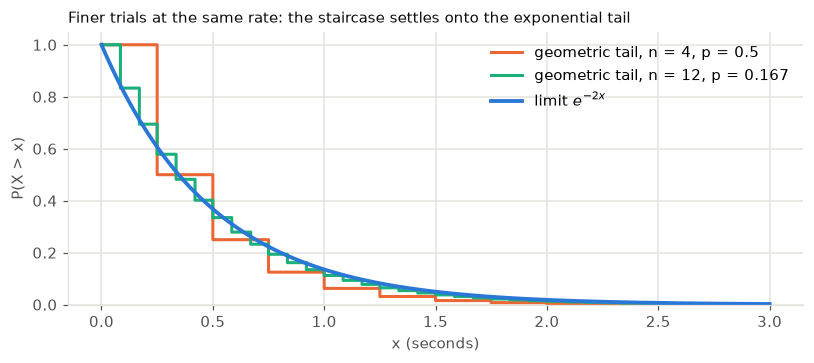

In [4]:
lam = 2
xs = np.linspace(0, 3, 601)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for n, color in [(4, ORANGE), (12, AQUA)]:
    ax.step(xs, (1 - lam / n) ** np.floor(n * xs), where="post", color=color, lw=2, label=f"geometric tail, n = {n}, p = {lam / n:.3g}")
ax.plot(xs, np.exp(-lam * xs), color=BLUE, lw=2.5, label=r"limit $e^{-2x}$")
ax.set(xlabel="x (seconds)", ylabel="P(X > x)", ylim=(0, 1.05))
ax.legend(frameon=False)
ax.set_title("Finer trials at the same rate: the staircase settles onto the exponential tail", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 2. The exponential distribution (slide 3)

**Motivation.** It extends the geometric distribution to continuous values.

**Meaning.** The time, or the distance, to a first success or a first failure.

**Parameter.** The rate $\lambda > 0$, the expected number of successes per unit, with the same meaning as in the Poisson.

**Range.** $\mathbb{R}_{\ge 0}$.

**PDF.**

$$f_\lambda(x) = \begin{cases} \lambda e^{-\lambda x} & x \ge 0 \\ 0 & x < 0. \end{cases}$$

The factor $e^{-\lambda x}$ gives the shape, and the leading $\lambda$ normalizes it. We write $X \sim E_\lambda$. The slides also use $Exp_\lambda$, and the subscript keeps $E_\lambda$ apart from an expectation $E[X]$.

Every density starts at height $f_\lambda(0) = \lambda$. A higher rate starts higher and falls faster, so the curves cross.

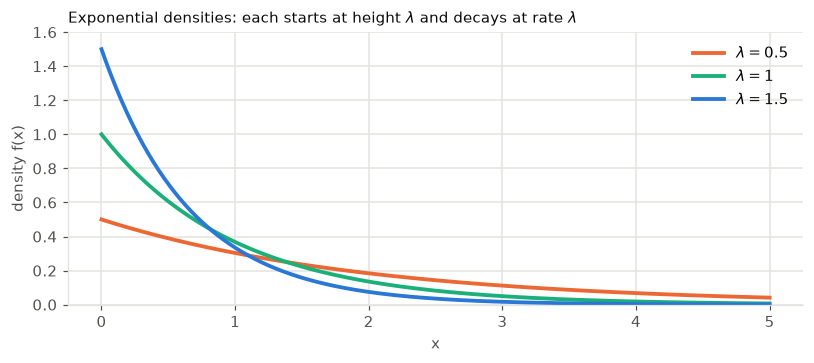

In [5]:
xs = np.linspace(0, 5, 501)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for lam, color in [(0.5, ORANGE), (1, AQUA), (1.5, BLUE)]:
    ax.plot(xs, lam * np.exp(-lam * xs), color=color, lw=2.5, label=f"$\\lambda = {lam}$")
ax.set(xlabel="x", ylabel="density f(x)", ylim=(0, 1.6))
ax.legend(frameon=False)
ax.set_title("Exponential densities: each starts at height $\\lambda$ and decays at rate $\\lambda$", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 3. Does it integrate to 1? (slide 4)

The density is nonnegative, so it remains to find the total area. Since $(-e^{-\lambda x})' = \lambda e^{-\lambda x}$, we have $\int \lambda e^{-\lambda x}\, dx = -e^{-\lambda x}$. Therefore

$$\int_{-\infty}^{\infty} f_\lambda(x)\, dx = \int_0^\infty \lambda e^{-\lambda x}\, dx = -e^{-\lambda x} \Big|_0^\infty = 0 - (-1) = 1.$$

In [6]:
for lam in [0.5, 1, 1.5, 10]:
    area, _ = quad(lambda x: lam * exp(-lam * x), 0, np.inf)
    print(f"lambda = {lam}: area = {area:.6f}")

lambda = 0.5: area = 1.000000
lambda = 1: area = 1.000000
lambda = 1.5: area = 1.000000
lambda = 10: area = 1.000000


## 4. Who is exponential? (slide 5)

These quantities are roughly exponential, and the word "roughly" matters (see Section 16):

- The duration of a phone call, or the time spent on hold.
- The time to failure of a system.
- The lifetime of a device.
- The time between accidents.
- A service time, which returns in Section 19.

They share one feature: the event can happen at any moment, and the chance of it happening soon does not build up over time.

## 5. The CDF (slide 6)

We started from the tail, so integrating the density must return to it. For $x \ge 0$,

$$P(X > x) = \int_x^\infty \lambda e^{-\lambda u}\, du = -e^{-\lambda u} \Big|_x^\infty = e^{-\lambda x},$$

and $P(X > x) = 1$ for $x \le 0$. Therefore

$$F(x) = P(X \le x) = \begin{cases} 1 - e^{-\lambda x} & x \ge 0 \\ 0 & x \le 0. \end{cases}$$

This closed form is a real convenience. The normal distribution in Module 04 has no such formula.

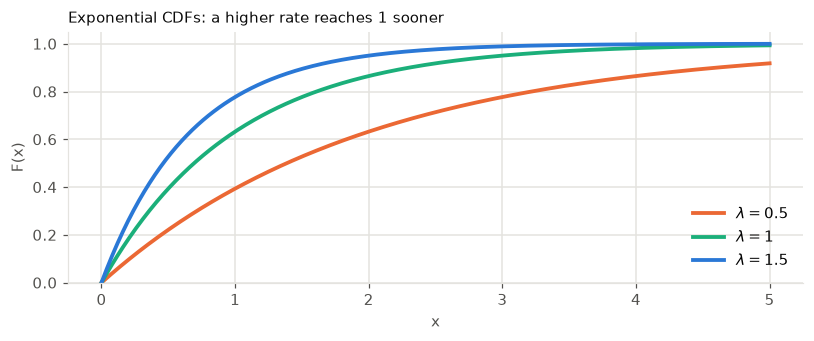

In [7]:
xs = np.linspace(0, 5, 501)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
for lam, color in [(0.5, ORANGE), (1, AQUA), (1.5, BLUE)]:
    ax.plot(xs, 1 - np.exp(-lam * xs), color=color, lw=2.5, label=f"$\\lambda = {lam}$")
ax.set(xlabel="x", ylabel="F(x)", ylim=(0, 1.05))
ax.legend(frameon=False, loc="lower right")
ax.set_title("Exponential CDFs: a higher rate reaches 1 sooner", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 6. Interval probability (slide 7)

For $0 \le a \le b$, endpoints do not matter for a continuous variable, and

$$P(a \le X \le b) = P(a < X < b) = F(b) - F(a) = (1 - e^{-\lambda b}) - (1 - e^{-\lambda a}) = e^{-\lambda a} - e^{-\lambda b}.$$

As $b$ grows, the probability climbs to $e^{-\lambda a}$, and the gap $e^{-\lambda b}$ shrinks exponentially fast. Most of the probability beyond $a$ sits just after $a$.

In [8]:
lam, a = 1, 1
X = rng.exponential(1 / lam, size=1_000_000)
print(f"limit e^(-lam a) = {exp(-lam * a):.4f}\n")
print(" b    exact    simulated")
for b in [1.5, 2, 3, 5, 10]:
    print(f"{b:4}  {exp(-lam * a) - exp(-lam * b):.4f}   {np.mean((X >= a) & (X <= b)):.4f}")

limit e^(-lam a) = 0.3679

 b    exact    simulated
 1.5  0.1447   0.1452
   2  0.2325   0.2329
   3  0.3181   0.3187
   5  0.3611   0.3620
  10  0.3678   0.3687


## 7. Integration by parts (slide 8)

The next two sections rely on this reminder. Starting from the product rule $d(uv) = u\, dv + v\, du$, rearrange and integrate:

$$\int u\, dv = uv - \int v\, du.$$

So one factor gets differentiated ($u$) and the other gets integrated ($dv$). The aim is a simpler integral on the right.

## 8. Expectation (slide 9)

Take $u = x$ and $dv = \lambda e^{-\lambda x}\, dx$, so $du = dx$ and $v = -e^{-\lambda x}$:

$$E[X] = \int_0^\infty x \lambda e^{-\lambda x}\, dx = -x e^{-\lambda x} \Big|_0^\infty + \int_0^\infty e^{-\lambda x}\, dx = 0 - \frac{1}{\lambda} e^{-\lambda x} \Big|_0^\infty = \frac{1}{\lambda}.$$

**Sanity check.** With $\lambda$ occurrences per second on average, the first one should come at around $1/\lambda$ seconds.

## 9. Variance (slide 10)

Take $u = x^2$ and the same $dv$, so $du = 2x\, dx$ and $v = -e^{-\lambda x}$:

$$E[X^2] = -x^2 e^{-\lambda x} \Big|_0^\infty + \int_0^\infty 2x e^{-\lambda x}\, dx = 0 + \frac{2}{\lambda} \int_0^\infty x \lambda e^{-\lambda x}\, dx = \frac{2}{\lambda} E[X] = \frac{2}{\lambda^2}.$$

The first integral is recycled instead of being solved again. Now

$$V(X) = E[X^2] - (E[X])^2 = \frac{2}{\lambda^2} - \frac{1}{\lambda^2} = \frac{1}{\lambda^2}, \qquad \sigma = \frac{1}{\lambda}.$$

So $\sigma = \mu$ for every exponential. As $\lambda$ grows, the distribution concentrates near 0 and $\sigma$ falls.

In [9]:
print("lambda   mean: exact, numeric, simulated     std: exact, numeric, simulated")
for lam in [0.5, 1, 1.5, 4]:
    m1, _ = quad(lambda x: x * lam * exp(-lam * x), 0, np.inf)
    m2, _ = quad(lambda x: x ** 2 * lam * exp(-lam * x), 0, np.inf)
    X = rng.exponential(1 / lam, size=1_000_000)
    print(f"{lam:5}   {1 / lam:7.4f} {m1:7.4f} {X.mean():7.4f}        {1 / lam:7.4f} {sqrt(m2 - m1 ** 2):7.4f} {X.std():7.4f}")

lambda   mean: exact, numeric, simulated     std: exact, numeric, simulated
  0.5    2.0000  2.0000  1.9988         2.0000  2.0000  2.0013
    1    1.0000  1.0000  0.9998         1.0000  1.0000  1.0003
  1.5    0.6667  0.6667  0.6674         0.6667  0.6667  0.6674
    4    0.2500  0.2500  0.2504         0.2500  0.2500  0.2502


## 10. Median (slide 11)

The median $m$ splits the probability in half: $P(X \le m) = P(X \ge m) = \frac{1}{2}$. With the right CDF,

$$e^{-\lambda m} = \frac{1}{2} \quad \Longrightarrow \quad e^{\lambda m} = 2 \quad \Longrightarrow \quad m = \frac{\ln 2}{\lambda} = \ln 2 \cdot \mu \approx 0.7\mu.$$

**Why is $\mu \ge m$?** The median only cares that a value is large, not how large. The mean is pulled up by the long right tail. So half of all devices with mean life 10 years fail within about 7 years.

In [10]:
lam = 0.5
X = rng.exponential(1 / lam, size=1_000_000)
print(f"median: exact {log(2) / lam:.4f}, simulated {np.median(X):.4f}")
print(f"mean:   exact {1 / lam:.4f}, simulated {X.mean():.4f}")
print(f"ratio median/mean: exact {log(2):.4f}, simulated {np.median(X) / X.mean():.4f}")
print(f"P(X > mean) = e^(-1) = {exp(-1):.4f}, simulated {np.mean(X > 1 / lam):.4f}")

median: exact 1.3863, simulated 1.3844
mean:   exact 2.0000, simulated 1.9984
ratio median/mean: exact 0.6931, simulated 0.6928
P(X > mean) = e^(-1) = 0.3679, simulated 0.3675


## 11. Example: a new car (slide 12)

**Problem.** The time until a new car's first failure is exponential with mean 2 years. Is the first failure during the first 4 years less or more likely than $\frac{1}{2}$? And how likely is a first failure between years 3 and 4?

**Guess.** We expect a failure at around 2 years, so one before year 4 should be very likely.

**Solution.** From $2 = \mu = 1/\lambda$ we get $\lambda = \frac{1}{2}$. The right CDF gives

$$P(X > 4) = e^{-4/2} = e^{-2} \approx 0.135, \qquad P(X \le 4) \approx 1 - 0.135 = 0.865.$$

For the middle interval,

$$P(3 < X \le 4) = P(X \ge 3) - P(X \ge 4) = e^{-3/2} - e^{-4/2} \approx 0.223 - 0.135 = 0.088.$$

In [11]:
lam = 1 / 2
X = rng.exponential(1 / lam, size=2_000_000)
print(f"P(X <= 4):     exact {1 - exp(-lam * 4):.4f}, simulated {np.mean(X <= 4):.4f}")
print(f"P(3 < X <= 4): exact {exp(-lam * 3) - exp(-lam * 4):.4f}, simulated {np.mean((X > 3) & (X <= 4)):.4f}")

P(X <= 4):     exact 0.8647, simulated 0.8645
P(3 < X <= 4): exact 0.0878, simulated 0.0877


## 12. Scaling (slide 13)

**Question.** Let $X \sim E_\lambda$ and let $a > 0$ be a constant. What is the distribution of $Y = aX$?

**Derivation.** With $x = y/a$, the change-of-variables formula gives, for $y \ge 0$,

$$f_Y(y) = \frac{f_X(x)}{\lvert (ax)' \rvert} \Bigg|_{x = y/a} = \frac{\lambda e^{-\lambda y/a}}{a} = \frac{\lambda}{a} \cdot e^{-\frac{\lambda}{a} y}.$$

So $Y \sim E_{\lambda/a}$. **Exponentials are closed under scaling by a positive constant.**

**Why it works.** The family's formula uses $x$ only through a product $c \cdot x$, here $\lambda x$. Scaling $x$ just changes the constant $c$, and the result stays in the family.

**Direction of the change.** Stretching time by $a$ makes events $a$ times rarer per unit, so the rate falls to $\lambda/a$ and the mean rises to $a/\lambda$. The summary on slide 19 writes $\alpha X \sim E_{\alpha\lambda}$, which is a typo for $E_{\lambda/\alpha}$, as this derivation shows.

**Example.** A lifetime with mean 2 years has rate $\frac{1}{2}$ per year. In months, multiply by 12: the rate is $\frac{1}{24}$ per month, and the mean is 24 months.

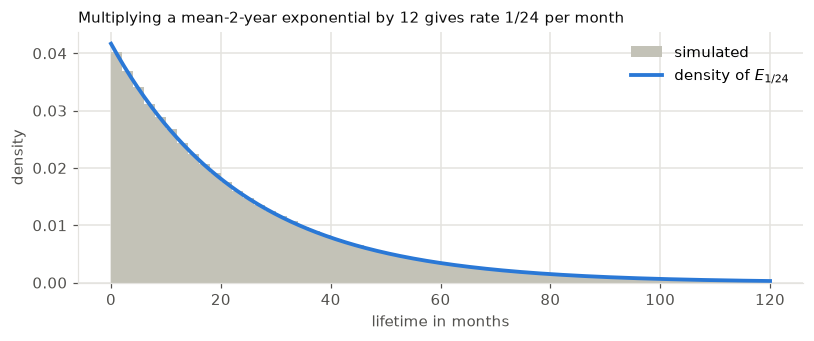

mean in months: exact 24.00, simulated 24.00
P(Y > 30): exact 0.2865, simulated 0.2868


In [12]:
years = rng.exponential(2, size=1_000_000)
months = 12 * years
rate = 1 / 24

fig, ax = plt.subplots(figsize=(7.5, 3.2))
hist_vs_density(ax, months, lambda y: rate * np.exp(-rate * y), 0, 120, "density of $E_{1/24}$", bins=60)
ax.set(xlabel="lifetime in months", ylabel="density")
ax.legend(frameon=False)
ax.set_title("Multiplying a mean-2-year exponential by 12 gives rate 1/24 per month", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

print(f"mean in months: exact {1 / rate:.2f}, simulated {months.mean():.2f}")
print(f"P(Y > 30): exact {exp(-rate * 30):.4f}, simulated {np.mean(months > 30):.4f}")

## 13. The effect of conditioning (slide 14)

A car was expected to last 2 years, and it has already run 4 years with no failure. From now on, do you expect it to last more or less than 2 further years?

- **"More."** It has proved itself a good car, or good karma is at work.
- **"Less."** It is older, its luck will run out, and a failure is overdue. This is a close relative of the gambler's fallacy.
- **If the time is exponential:** still 2 years.

## 14. Memorylessness (slide 15)

**Claim.** For $X \sim E_\lambda$ and $a, b \ge 0$,

$$P(X \ge a + b \mid X \ge a) = P(X \ge b).$$

**Proof.** Use $P(B \mid A) = P(A, B)/P(A)$. The event $X \ge a + b$ is contained in $X \ge a$, so the intersection is just $X \ge a + b$. Then, with $P(X \ge a) = e^{-\lambda a}$,

$$P(X \ge a + b \mid X \ge a) = \frac{P(X \ge a + b,\, X \ge a)}{P(X \ge a)} = \frac{P(X \ge a + b)}{P(X \ge a)} = \frac{e^{-\lambda(a + b)}}{e^{-\lambda a}} = e^{-\lambda b} = P(X \ge b).$$

**In words.** Given survival to time $a$, the remaining life has the same distribution as a brand-new one. This is memorylessness, as for the geometric distribution. The exponential is the **only** memoryless distribution over $\mathbb{R}^+$ (Problem 10 proves this).

**Consequences.**

- Complements: $P(X < a + b \mid X \ge a) = 1 - P(X \ge a + b \mid X \ge a) = 1 - P(X \ge b) = P(X < b)$.
- Conditional density: $f(X = a + b \mid X \ge a) = f(X = b)$.
- Conditional mean: $E[X \mid X \ge a] = E[X] + a$. The total lifetime is the age so far plus a fresh mean.

Compare Session 1, where a uniform lifetime aged: its chance of 2 more years fell as it got older.

In [13]:
lam = 0.5
X = rng.exponential(1 / lam, size=5_000_000)

print(" a   b   P(X>=a+b | X>=a)   P(X>=b)   exact e^(-lam b)")
for a, b in [(1, 1), (3, 1), (6, 1), (2, 3), (5, 3)]:
    survivors = X[X >= a]
    print(f"{a:2}  {b:2}       {np.mean(survivors >= a + b):.4f}         {np.mean(X >= b):.4f}      {exp(-lam * b):.4f}")

print()
for a in [1, 3, 6]:
    print(f"E[X | X >= {a}]: exact {a + 1 / lam:.3f}, simulated {X[X >= a].mean():.3f}")

 a   b   P(X>=a+b | X>=a)   P(X>=b)   exact e^(-lam b)
 1   1       0.6065         0.6063      0.6065
 3   1       0.6065         0.6063      0.6065
 6   1       0.6048         0.6063      0.6065
 2   3       0.2233         0.2232      0.2231
 5   3       0.2228         0.2232      0.2231



E[X | X >= 1]: exact 3.000, simulated 3.000
E[X | X >= 3]: exact 5.000, simulated 5.000
E[X | X >= 6]: exact 8.000, simulated 7.997


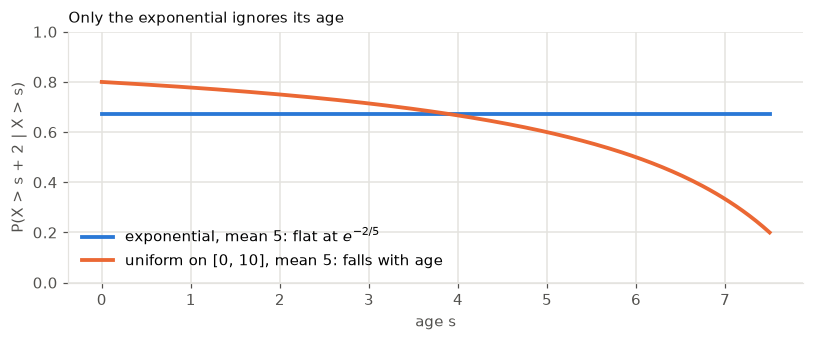

In [14]:
# Survival chance over the next 2 years, as a function of age, for two lifetimes with mean 5.
ages = np.linspace(0, 7.5, 200)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(ages, np.full_like(ages, exp(-2 / 5)), color=BLUE, lw=2.5, label="exponential, mean 5: flat at $e^{-2/5}$")
ax.plot(ages, (8 - ages) / (10 - ages), color=ORANGE, lw=2.5, label="uniform on [0, 10], mean 5: falls with age")
ax.set(xlabel="age s", ylabel="P(X > s + 2 | X > s)", ylim=(0, 1))
ax.legend(frameon=False, loc="lower left")
ax.set_title("Only the exponential ignores its age", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 15. Example: like new (slide 16)

**Problem.** As in Section 11, the time to first failure is exponential with mean 2 years. You buy a 10-year-old car with no prior failure. What is the chance of a first failure in the first 4 years after you buy it, and in the fourth year after you buy it?

**Solution.** The clock has effectively been reset.

- First 4 years after buying (car ages 10 to 14): $P(X \le 14 \mid X \ge 10) = P(X \le 4) \approx 0.865$.
- Between 3 and 4 years after buying (car ages 13 to 14): $P(13 < X \le 14 \mid X \ge 10) = P(3 < X \le 4) \approx 0.088$.

These are exactly the new-car answers from Section 11.

In [15]:
X = rng.exponential(2, size=8_000_000)
old = X[X >= 10]
print(f"cars that reach age 10: {old.size:,} of {X.size:,}")
print(f"P(X <= 14 | X >= 10):      exact {1 - exp(-2):.4f}, simulated {np.mean(old <= 14):.4f}")
print(f"P(13 < X <= 14 | X >= 10): exact {exp(-1.5) - exp(-2):.4f}, simulated {np.mean((old > 13) & (old <= 14)):.4f}")

cars that reach age 10: 53,842 of 8,000,000
P(X <= 14 | X >= 10):      exact 0.8647, simulated 0.8633


P(13 < X <= 14 | X >= 10): exact 0.0878, simulated 0.0876


## 16. Modifications (slide 17)

We modeled time to failure as exponential. Your experience may disagree:

- **Older cars break more often.** So the time to failure is not truly exponential. It may be close, with a $\lambda$ that slowly increases over time.
- **A car with a prior failure** probably has a different $\lambda$.

## 17. All models are wrong (slide 18)

George Box (1919-2013) was a statistician who contributed to Bayesian inference, experimental design, and more. He also married Ronald Fisher's daughter. His best-known line is that all models are wrong, but some are useful.

A model cannot be exact, since it only approximates reality. It still helps us understand, plan, and act. The exponential is a clear example: it is false for an aging car, but it gives simple answers that are often close enough to act on.

## 18. Summary of the family (slide 19)

| Item | $X \sim E_\lambda$ |
|---|---|
| Significance | Time or distance to a first success, the geometric made continuous |
| Parameter | Rate $\lambda > 0$, the expected number of successes per unit, as in the Poisson |
| PDF | $f_\lambda(x) = \lambda e^{-\lambda x}$, $x \ge 0$ |
| CDF | $F(x) = 1 - e^{-\lambda x}$ |
| Mean, variance, std | $1/\lambda$, $\;1/\lambda^2$, $\;1/\lambda$ |
| Median | $\ln 2 \cdot \mu \approx 0.7\mu$ |
| Scaling | $\alpha X \sim E_{\lambda/\alpha}$ for $\alpha > 0$ |
| Memoryless | $f(X = a + b \mid X > a) = f(X = b)$ |
| Python | `scipy.stats.expon`, which takes `scale` $= 1/\lambda$ and not the rate |

In [16]:
lam = 0.5
d = expon(scale=1 / lam)  # scale is the mean 1/lambda, not the rate
print(f"mean {d.mean():.4f}, variance {d.var():.4f}, std {d.std():.4f}, median {d.median():.4f}")
print(f"cdf(4) = {d.cdf(4):.4f}, sf(4) = {d.sf(4):.4f}, pdf(0) = {d.pdf(0):.4f}")
print(f"a common slip, expon(scale=lam), has mean {expon(scale=lam).mean():.4f} instead of {1 / lam:.4f}")

mean 2.0000, variance 4.0000, std 2.0000, median 1.3863
cdf(4) = 0.8647, sf(4) = 0.1353, pdf(0) = 0.5000
a common slip, expon(scale=lam), has mean 0.5000 instead of 2.0000


## 19. Service times (deck 6, slides 1-2)

A **service time** is the time needed to process a request: to complete a transaction, send a response, or serve a customer.

Suppose that at every instant, the job has the same chance of completing. Then the service time is exponentially distributed, and so it is memoryless. Deck 6 draws one consequence of this. It describes itself as having not much math but an important moral.

## 20. Beating the crowds (deck 6, slides 3-6)

**The story.** You need to go to the DMV and do not want to wait long. You wake up at dawn and sprint there, and two other people arrive at exactly the same moment. The DMV has two servers.

**Back in the day.** The three of you would agree on a random order, and then

$$P(\text{calamity}) = P(\text{you finish last}) = \frac{1}{3}.$$

Not so bad.

**Not anymore.** One person jumps the line, then the other does, and now you are last. Should you be mad?

**Before probability.** If service took a constant 5 minutes, then both others would finish at minute 5, and you at minute 10. You would finish last for sure, even with two servers, so $P(\text{finish last})$ jumps from $\frac{1}{3}$ to $1$. Definitely mad.

**Can probability help?** Service times are not constant. They are random, and often modeled as exponential.

## 21. Exponential service (deck 6, slide 7)

Both servers start on the two line-jumpers. One finishes first, and you join. **Now two of you are being served.** You started later, but the service time is exponential, hence memoryless: the other person's remaining time has the same distribution as your fresh one. It does not matter who started last. By symmetry,

$$P(\text{you finish last}) = \frac{1}{2}.$$

**In symbols.** If $A$ and $B$ are the two service times and $Y$ is yours, then you finish last exactly when $Y > \lvert A - B \rvert$. The simulation below compares that event for the two service models with the same mean.

In [17]:
n = 2_000_000
A, B, Y = rng.exponential(5, size=(3, n))
print(f"exponential service: P(you finish last) = {np.mean(Y > np.abs(A - B)):.4f}  (exact 1/2)")

A_c, B_c, Y_c = np.full((3, n), 5.0)
print(f"constant service:    P(you finish last) = {np.mean(Y_c > np.abs(A_c - B_c)):.4f}  (exact 1)")

fair = rng.integers(0, 3, size=n)  # your place in a random order, for exponential service
finish = np.column_stack([A, B, np.minimum(A, B) + Y])  # the third place starts when a server frees up
print(f"fair random order:   P(you finish last) = {np.mean(finish.argmax(axis=1) == fair):.4f}  (exact 1/3)")

exponential service: P(you finish last) = 0.4998  (exact 1/2)
constant service:    P(you finish last) = 1.0000  (exact 1)
fair random order:   P(you finish last) = 0.3334  (exact 1/3)


## 22. Conclusion (deck 6, slide 8)

If the order were fair, you would finish last with probability $\frac{1}{3}$. The line-jumpers did not raise this to $1$. They raised it to $\frac{1}{2}$, a small increase of just $\frac{1}{6}$. Is that worth all the anger?

## 23. Quiz: more servers (deck 6, slide 9)

**Question.** There are $s$ servers and more people in line, and you are last. What is $P(\text{you finish last})$?

**Answer.**

- **Deterministic service:** you start last, so nobody finishes after you, with probability $1$. (If the line length is such that others started at the same moment, you tie with them, which is no comfort.) Angry.
- **Exponential service:** when you start, $s - 1$ others are in service. All $s$ remaining times are memoryless and identically distributed, so each of you is equally likely to be last: $\frac{1}{s}$. Even better than $\frac{1}{2}$.

Note that the length of the line does not affect the answer, only the number of servers.

In [18]:
def finish_last_prob(s, ahead, draw, trials=60_000):
    # A first-come line with s servers, where you come after `ahead` customers.
    times = draw((trials, ahead + 1))
    last = 0
    for row in times:
        free = [0.0] * s  # the time at which each server next becomes free
        for t in row[:-1]:
            heapq.heapreplace(free, free[0] + t)
        mine = free[0] + row[-1]
        last += mine >= max(free[1:], default=0.0)  # a tie counts: nobody finishes after you
    return last / trials


exponential = lambda shape: rng.exponential(1, size=shape)
constant = lambda shape: np.ones(shape)

print("servers  ahead   exponential (exact 1/s)   constant (exact 1)")
for s, ahead in [(2, 2), (2, 6), (3, 3), (3, 9), (5, 5), (5, 12)]:
    print(f"{s:6} {ahead:6}      {finish_last_prob(s, ahead, exponential):.4f} ({1 / s:.4f})         {finish_last_prob(s, ahead, constant, 2_000):.4f}")

servers  ahead   exponential (exact 1/s)   constant (exact 1)


     2      2      0.5003 (0.5000)         1.0000


     2      6      0.4993 (0.5000)         1.0000


     3      3      0.3324 (0.3333)         1.0000


     3      9      0.3340 (0.3333)         1.0000


     5      5      0.2028 (0.2000)         1.0000


     5     12      0.2014 (0.2000)         1.0000

## 24. The moral (deck 6, slide 10)

There is not much probability here, but there is a life lesson. Lines are long and the world may seem to be getting worse, yet with exponential service times, starting behind is not so bad. More generally, random luck changes, and being behind now says little about who finishes first.

## Common pitfalls

1. **Mixing up the rate and the mean.** $\lambda$ is a rate, and the mean is $1/\lambda$. A mean of 2 years means $\lambda = \frac{1}{2}$, not $\lambda = 2$.
2. **Scaling the rate the wrong way.** $aX$ has rate $\lambda/a$. Slide 19's $E_{\alpha\lambda}$ is a typo. Check with the mean: $aX$ has mean $a/\lambda$.
3. **Treating the density as a probability.** $f(0) = \lambda$ exceeds 1 when $\lambda > 1$, which is fine. Probabilities come from $e^{-\lambda a} - e^{-\lambda b}$.
4. **Assuming the mean is the typical value.** The median is only about $0.7\mu$, and about 63% of values fall below the mean. Only $e^{-1} \approx 0.37$ exceed it.
5. **Using memorylessness on something else.** It is special to the exponential among continuous distributions on $\mathbb{R}^+$. A uniform lifetime ages.
6. **Comparing to the wrong unconditional probability.** $P(X \ge a + b \mid X \ge a)$ equals $P(X \ge b)$, not $P(X \ge a + b)$.
7. **Reading $E[X \mid X \ge a]$ as $1/\lambda$.** That is the mean *remaining* time. The mean total is $a + 1/\lambda$.
8. **Assuming shifts stay exponential.** The family is closed under positive scaling only. $X + c$ cannot take values below $c$, so it is not exponential.
9. **Passing the rate to `scipy.stats.expon`.** It takes `scale` $= 1/\lambda$.
10. **Expecting the answer $\frac{1}{s}$ for any random service time.** It relies on memorylessness. Uniform service with two servers gives $\frac{2}{3}$ (Problem 12).

## Key takeaways

- **Origin:** many rare trials at rate $\lambda = np$ give $P(X > x) = (1 - \lambda/n)^{nx} \to e^{-\lambda x}$, and only $\lambda$ remains.
- **Formulas:** $f(x) = \lambda e^{-\lambda x}$, $\;F(x) = 1 - e^{-\lambda x}$, $\;P(X > x) = e^{-\lambda x}$, for $x \ge 0$.
- **Intervals:** $P(a \le X \le b) = e^{-\lambda a} - e^{-\lambda b}$.
- **Moments:** $\mu = \sigma = 1/\lambda$, $V = 1/\lambda^2$, and the median is $\ln 2 \cdot \mu \approx 0.7\mu$.
- **Scaling:** $aX \sim E_{\lambda/a}$ for $a > 0$.
- **Memoryless:** $P(X \ge a + b \mid X \ge a) = P(X \ge b)$ and $E[X \mid X \ge a] = a + 1/\lambda$. The exponential is the only such distribution on $\mathbb{R}^+$.
- **Examples:** mean 2 years gives $P(X \le 4) \approx 0.865$ and $P(3 < X \le 4) \approx 0.088$, and a 10-year-old car gets the same two answers.
- **Models:** all are wrong, some are useful.
- **Service times:** being jumped raises $P(\text{finish last})$ from $\frac{1}{3}$ to $1$ under constant service, but only to $\frac{1}{2}$ under exponential service. With $s$ servers, it is $\frac{1}{s}$.
- Next: Module 04 turns to the normal (Gaussian) distribution, the bell curve that appears when many independent factors add up.